# **Import Library & Load Dataset**

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# 1. Load Data
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

print(f"Data Train: {train.shape}")
print(f"Data Test : {test.shape}")

Data Train: (533465, 17)
Data Test : (228629, 16)


# **Cek Struktur Data & Missing Values**

In [2]:
# Tampilkan 5 baris pertama data train
display(train.head())

# Informasi tipe data dan kolom
print("--- Ringkasan Data Train ---")
print(train.info())

# Cek missing values
missing_train = train.isnull().sum()
missing_train = missing_train[missing_train > 0]
print("\n--- Missing Values di Data Train ---")
print(missing_train if not missing_train.empty else "Tidak ada missing values!")

,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


--- Ringkasan Data Train ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   building_id             533465 non-null  int64 
 1   district_id             533465 non-null  int64 
 2   vdcmun_id               533465 non-null  int64 
 3   ward_id                 533465 non-null  int64 
 4   count_floors_pre_eq     533465 non-null  int64 
 5   age_building            533465 non-null  int64 
 6   plinth_area_sq_ft       533465 non-null  int64 
 7   height_ft_pre_eq        533465 non-null  int64 
 8   land_surface_condition  533465 non-null  object
 9   foundation_type         533465 non-null  object
 10  roof_type               533465 non-null  object
 11  ground_floor_type       533465 non-null  object
 12  other_floor_type        533465 non-null  object
 13  position                533465 non-null  object
 14  plan_co

# **Cek Distribusi Target Label**

C:\Users\Azizah Adilah\AppData\Local\Temp\ipykernel_14404\3795951726.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=train, x='damage_grade', order=['Grade 1', 'Grade 2', 'Grade 3', 'Grade 4', 'Grade 5'], palette='viridis')


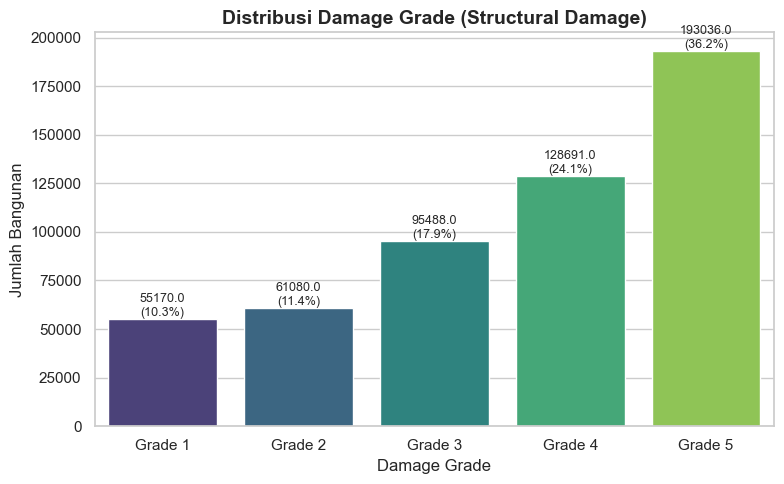

In [3]:
os.makedirs('../reports/figures', exist_ok=True)

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=train, x='damage_grade', order=['Grade 1', 'Grade 2', 'Grade 3', 'Grade 4', 'Grade 5'], palette='viridis')
plt.title("Distribusi Damage Grade (Structural Damage)", fontsize=14, fontweight="bold")
plt.xlabel("Damage Grade")
plt.ylabel("Jumlah Bangunan")

total = len(train)
for p in ax.patches:
    height = p.get_height()
    percentage = f'{100 * height / total:.1f}%'
    ax.annotate(f'{height}\n({percentage})', (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('../reports/figures/target_distribution.png', dpi=300)
plt.show()

# **Correlation Heatmap Fitur Numerik**

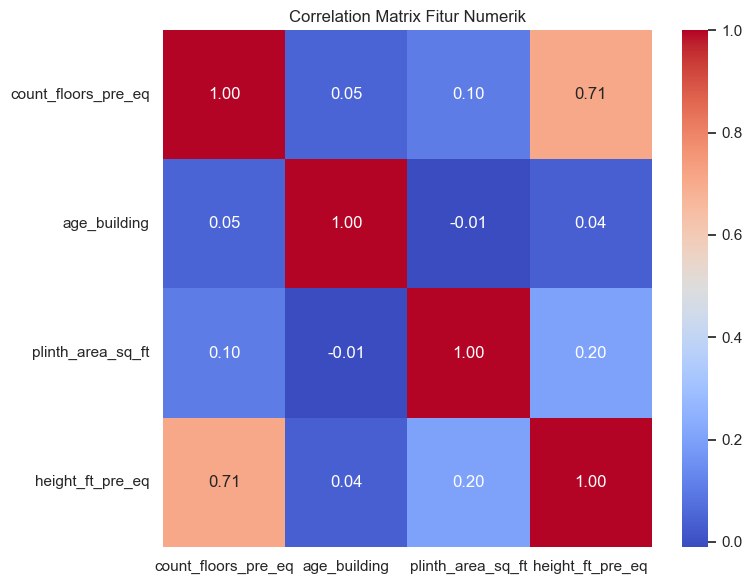

In [4]:
num_cols = ['count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq']
plt.figure(figsize=(8, 6))
sns.heatmap(train[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix Fitur Numerik")
plt.tight_layout()
plt.savefig('../reports/figures/correlation_heatmap.png', dpi=300)
plt.show()

# **Temuan Penting: Pola pada `building_id`**
Bangunan dengan `building_id` berurutan cenderung disurvei bersamaan sehingga tingkat kerusakannya mirip. Ini menjadi dasar fitur tetangga (`NeighborTargetFeatures`) di `scripts/feature_engineering.py`.

In [5]:
tr = pd.read_csv('../data/train.csv', dtype={'building_id': str})
tr['grade'] = tr['damage_grade'].str[-1].astype(int)
tr_sorted = tr.sort_values('building_id').reset_index(drop=True)

same_adjacent = (tr_sorted['grade'].values[1:] == tr_sorted['grade'].values[:-1]).mean()
random_baseline = (tr['grade'].value_counts(normalize=True) ** 2).sum()
print(f"Tetangga langsung (urut building_id) dengan grade sama : {same_adjacent:.1%}")
print(f"Peluang kesamaan jika acak                             : {random_baseline:.1%}")

Tetangga langsung (urut building_id) dengan grade sama : 51.9%
Peluang kesamaan jika acak                             : 24.5%
